# Future-session charging-energy prediction

This notebook runs the reproducible Dataset 1 experiment documented in `docs/ML_EXPERIMENT.md`. The target is reported delivered session energy (`energy_session`, kWh), conditional on a residential charging session being recorded. It does not predict charging occurrence, location choice, SoC, or national demand.

The implementation builds only plug-in-time features and causal user history. It reports a future-session chronological test and a separate unseen-user holdout.

In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Image, display, Markdown

# Keep local notebook execution single-process on restricted Windows environments.
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')

root = Path.cwd().resolve()
if not (root / 'data' / 'raw' / 'norway_ev').exists():
    root = root.parent
sys.path.insert(0, str(root))

from src.models.session_energy import run_experiment


## Run the experiment

This overwrites only the two ML outputs: `outputs/ml_metrics.csv` and `outputs/ml_actual_vs_predicted.png`.

In [2]:
metrics, predictions, metadata = run_experiment(root)
display(Markdown('### Split summary'))
display(metadata)
display(Markdown('### Evaluation metrics (kWh)'))
display(metrics)


### Split summary

{'target': 'energy_session',
 'temporal_cutoff': '2020-01-26 00:16:34',
 'temporal_train_sessions': 28301,
 'temporal_test_sessions': 7076,
 'temporal_train_users': 220,
 'temporal_test_users': 228,
 'temporal_warm_sessions': 3643,
 'temporal_cold_sessions': 3433,
 'group_train_sessions': 26483,
 'group_test_sessions': 8894,
 'group_train_users': 213,
 'group_test_users': 54}

### Evaluation metrics (kWh)

,evaluation,subset,predictor,n_sessions,n_users,mae_kwh,rmse_kwh
0,future_session_chronological,all_test,training_median,7076,228,8.791461,13.312317
1,future_session_chronological,all_test,causal_user_history_median,7076,228,5.647456,8.897571
2,future_session_chronological,all_test,gradient_boosting,7076,228,5.612019,8.262289
3,future_session_chronological,warm_user,training_median,3643,181,8.398342,13.198546
4,future_session_chronological,warm_user,causal_user_history_median,3643,181,4.884391,7.948767
5,future_session_chronological,warm_user,gradient_boosting,3643,181,4.900009,7.460779
6,future_session_chronological,cold_start_user,training_median,3433,47,9.208628,13.431993
7,future_session_chronological,cold_start_user,causal_user_history_median,3433,47,6.457199,9.804508
8,future_session_chronological,cold_start_user,gradient_boosting,3433,47,6.367584,9.035402
9,unseen_user_group_holdout,all_test,training_median,8894,54,6.642320,9.781285


## Chronological test-set predictions

The figure samples at most 3,000 held-out later sessions for legibility. See the metrics table and methodology note for warm-user, cold-start, and unseen-user interpretation.

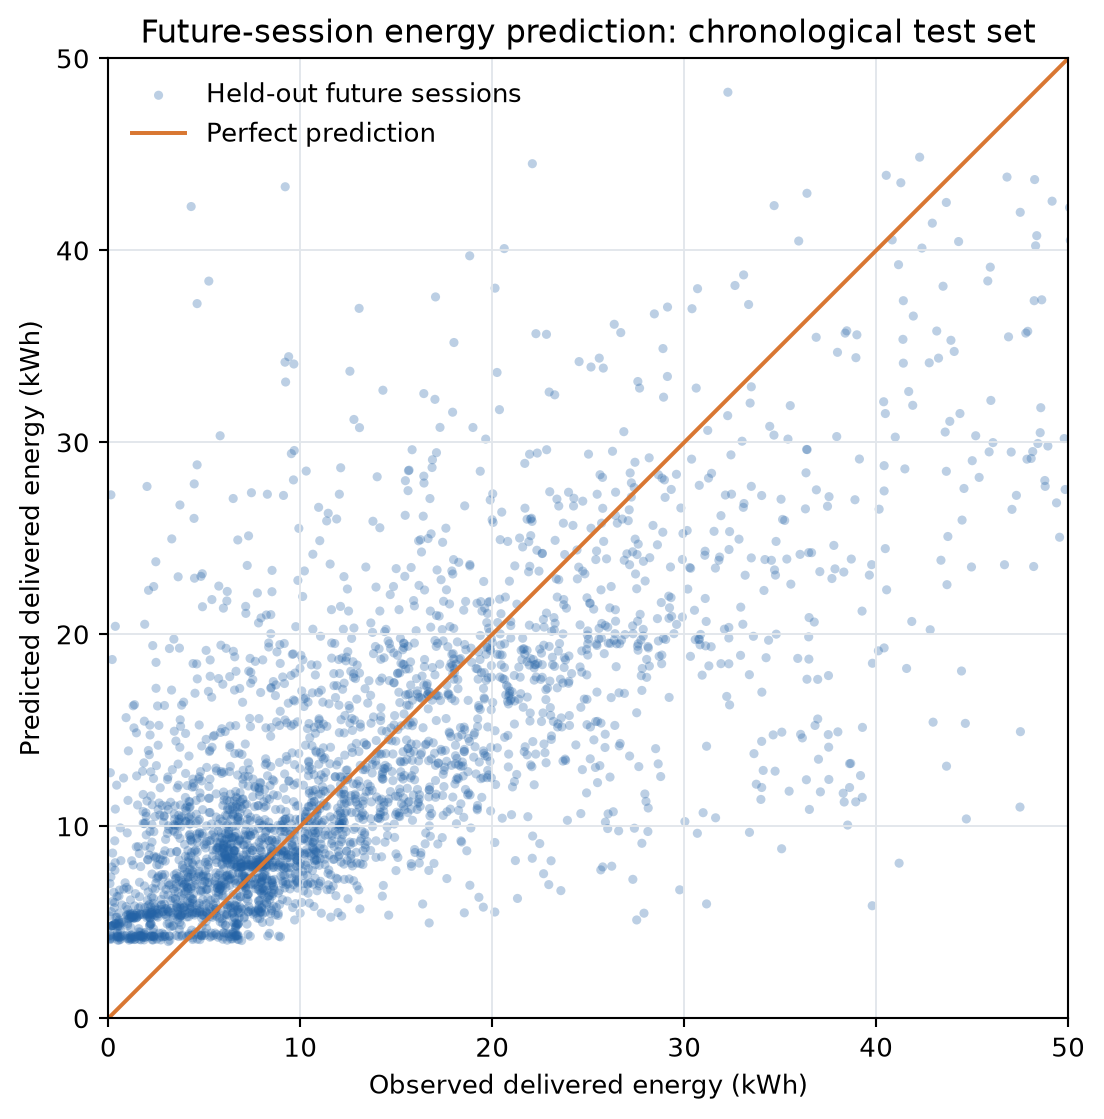

The detailed target definition, leakage controls, metrics, and limitations are in `docs/ML_EXPERIMENT.md`. The unseen-user result must be reported separately from the chronological future-session task.

In [3]:
display(Image(filename=root / 'outputs' / 'ml_actual_vs_predicted.png'))
display(Markdown(
    'The detailed target definition, leakage controls, metrics, and limitations are in '
    '`docs/ML_EXPERIMENT.md`. The unseen-user result must be reported separately from '
    'the chronological future-session task.'
))
